In [1]:
from google.colab import drive
drive.mount('/content/drive')

import os, sys, json, time
os.chdir('/content/drive/MyDrive/network-intrusion-ml')
sys.path.append('/content/drive/MyDrive/network-intrusion-ml')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.utils import (PROCESSED_DIR, METRIC_DIR, TABLE_DIR, save_fig, save_table,
                       log_experiment, RANDOM_STATE)

sns.set_theme(style="whitegrid")

with open(METRIC_DIR / "label_mapping.json") as f:
    label_mapping = json.load(f)
with open(METRIC_DIR / "feature_sets.json") as f:
    feature_sets = json.load(f)

FEATURES = feature_sets["CORR_FILTERED"]
class_names = [c for c, i in sorted(label_mapping.items(), key=lambda kv: kv[1])]
print("Features:", len(FEATURES))

Mounted at /content/drive
Features: 48


In [2]:
CV_FILE = PROCESSED_DIR / "cv_sample.parquet"
BIG = ["BENIGN", "DoS", "DDoS", "PortScan"]

if CV_FILE.exists():
    cv_df = pd.read_parquet(CV_FILE)
    print("Loaded the saved CV sample.")
else:
    train_df = pd.read_parquet(PROCESSED_DIR / "train.parquet")   # NOT test.parquet
    parts = []
    for cls, g in train_df.groupby("Label_Group"):
        parts.append(g.sample(frac=0.25, random_state=RANDOM_STATE) if cls in BIG else g)
    cv_df = pd.concat(parts).sample(frac=1, random_state=RANDOM_STATE).reset_index(drop=True)
    cv_df.to_parquet(CV_FILE, index=False)
    del train_df
    print("Built and saved the CV sample.")

print("CV sample rows:", f"{len(cv_df):,}")
print(cv_df["Label_Group"].value_counts())

X_cv = cv_df[FEATURES]
y_bin = cv_df["Binary"].values
y_multi = cv_df["Label_Group"].map(label_mapping).values

Built and saved the CV sample.
CV sample rows: 507,570
Label_Group
BENIGN          414451
DoS              38746
DDoS             25603
PortScan         18139
FTP-Patator       4745
SSH-Patator       2575
Web Attack        1715
Bot               1558
Infiltration        29
Heartbleed           9
Name: count, dtype: int64


In [3]:
from sklearn.model_selection import StratifiedKFold
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score)

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
folds = list(skf.split(X_cv, cv_df["Label_Group"]))

print("Each fold's quiz set:")
for k, (tr, va) in enumerate(folds, 1):
    c = cv_df["Label_Group"].iloc[va].value_counts()
    print(f"  Fold {k}: quiz on {len(va):,} rows | Heartbleed {c.get('Heartbleed', 0)}, "
          f"Infiltration {c.get('Infiltration', 0)}")

cv_models = {
    "XGBoost": lambda: XGBClassifier(n_estimators=100, max_depth=6, learning_rate=0.3,
                                     tree_method="hist", n_jobs=-1,
                                     random_state=RANDOM_STATE, verbosity=0),
    "Random Forest": lambda: RandomForestClassifier(n_estimators=100, n_jobs=-1,
                                                    random_state=RANDOM_STATE),
    "Decision Tree": lambda: DecisionTreeClassifier(random_state=RANDOM_STATE),
}

FOLD_CSV = TABLE_DIR / "06a_cv_fold_metrics.csv"

def fold_metrics(task, model, X_v, y_v):
    if task == "binary":
        proba = model.predict_proba(X_v)
        pred = model.classes_[proba.argmax(axis=1)]
        m = {"accuracy": accuracy_score(y_v, pred),
             "precision": precision_score(y_v, pred, zero_division=0),
             "recall": recall_score(y_v, pred, zero_division=0),
             "f1": f1_score(y_v, pred, zero_division=0),
             "roc_auc": roc_auc_score(y_v, proba[:, 1]),
             "pr_auc": average_precision_score(y_v, proba[:, 1])}
    else:
        pred = model.predict(X_v)
        present = np.unique(y_v)
        m = {"accuracy": accuracy_score(y_v, pred),
             "macro_precision": precision_score(y_v, pred, labels=present, average="macro", zero_division=0),
             "macro_recall": recall_score(y_v, pred, labels=present, average="macro", zero_division=0),
             "macro_f1": f1_score(y_v, pred, labels=present, average="macro", zero_division=0),
             "weighted_f1": f1_score(y_v, pred, average="weighted", zero_division=0)}
    return pred, m

def run_cv(task):
    """5-fold CV for every model. Saves after each finished model; finished models are skipped on re-run."""
    y_all = y_bin if task == "binary" else y_multi
    rows = pd.read_csv(FOLD_CSV).to_dict("records") if FOLD_CSV.exists() else []
    done = {(r["model"], r["task"]) for r in rows}

    for name, factory in cv_models.items():
        if (name, task) in done:
            print(f"[skip] {name} / {task} (already saved)")
            continue
        oof = np.zeros(len(y_all), dtype=np.int8)       # out-of-fold predictions
        for k, (tr, va) in enumerate(folds, 1):
            model = factory()
            t0 = time.time()
            model.fit(X_cv.iloc[tr], y_all[tr])
            fit_s = time.time() - t0
            pred, m = fold_metrics(task, model, X_cv.iloc[va], y_all[va])
            oof[va] = pred
            rows.append({"model": name, "task": task, "fold": k,
                         "train_seconds": round(fit_s, 1), **m})
            key = "f1" if task == "binary" else "macro_f1"
            print(f"{name:14s} fold {k}/5 | fit {fit_s:6.1f}s | {key} {m[key]:.4f}")

        np.save(METRIC_DIR / f"06a_oof_{name.replace(' ', '_')}_{task}.npy", oof)
        pd.DataFrame(rows).to_csv(FOLD_CSV, index=False)      # saved after each model

        mine = pd.DataFrame([r for r in rows if r["model"] == name and r["task"] == task])
        log_experiment(
            experiment_id=f"EXP-03_cv_{task}_{name}".replace(" ", "_"),
            task="Experiment A: binary" if task == "binary" else "Experiment B: multi-class (Label_Group)",
            model=name, features=f"CORR_FILTERED ({len(FEATURES)})",
            preprocessing="raw features (tree-based model)",
            hyperparameters="baseline defaults",
            split="stratified 5-fold CV on the CV sample (inside the training set)",
            metrics={k: round(float(mine[k].mean()), 4) for k in m.keys()},
            notes="mean over 5 folds; out-of-fold predictions saved in results/metrics",
        )
    print("Done:", task)

print("Helpers ready.")

Each fold's quiz set:
  Fold 1: quiz on 101,514 rows | Heartbleed 1, Infiltration 6
  Fold 2: quiz on 101,514 rows | Heartbleed 2, Infiltration 5
  Fold 3: quiz on 101,514 rows | Heartbleed 2, Infiltration 6
  Fold 4: quiz on 101,514 rows | Heartbleed 2, Infiltration 6
  Fold 5: quiz on 101,514 rows | Heartbleed 2, Infiltration 6
Helpers ready.


In [7]:
run_cv("binary")

[skip] XGBoost / binary (already saved)
Random Forest  fold 1/5 | fit  139.9s | f1 0.9951
Random Forest  fold 2/5 | fit  137.7s | f1 0.9950
Random Forest  fold 3/5 | fit  133.9s | f1 0.9954
Random Forest  fold 4/5 | fit  124.3s | f1 0.9955
Random Forest  fold 5/5 | fit  135.7s | f1 0.9958
[logged experiment] EXP-03_cv_binary_Random_Forest
Decision Tree  fold 1/5 | fit   24.5s | f1 0.9949
Decision Tree  fold 2/5 | fit   25.6s | f1 0.9939
Decision Tree  fold 3/5 | fit   25.6s | f1 0.9946
Decision Tree  fold 4/5 | fit   24.7s | f1 0.9951
Decision Tree  fold 5/5 | fit   25.3s | f1 0.9946
[logged experiment] EXP-03_cv_binary_Decision_Tree
Done: binary


In [8]:
run_cv("multiclass")

XGBoost        fold 1/5 | fit   89.3s | macro_f1 0.9682
XGBoost        fold 2/5 | fit   86.2s | macro_f1 0.9893
XGBoost        fold 3/5 | fit   85.8s | macro_f1 0.9505
XGBoost        fold 4/5 | fit   82.8s | macro_f1 0.9820
XGBoost        fold 5/5 | fit   98.9s | macro_f1 0.8828
[logged experiment] EXP-03_cv_multiclass_XGBoost
Random Forest  fold 1/5 | fit  155.0s | macro_f1 0.9670
Random Forest  fold 2/5 | fit  155.8s | macro_f1 0.9871
Random Forest  fold 3/5 | fit  151.7s | macro_f1 0.9679
Random Forest  fold 4/5 | fit  144.5s | macro_f1 0.9692
Random Forest  fold 5/5 | fit  141.4s | macro_f1 0.9355
[logged experiment] EXP-03_cv_multiclass_Random_Forest
Decision Tree  fold 1/5 | fit   26.4s | macro_f1 0.9362
Decision Tree  fold 2/5 | fit   28.5s | macro_f1 0.9844
Decision Tree  fold 3/5 | fit   27.6s | macro_f1 0.9767
Decision Tree  fold 4/5 | fit   26.0s | macro_f1 0.9602
Decision Tree  fold 5/5 | fit   25.6s | macro_f1 0.9603
[logged experiment] EXP-03_cv_multiclass_Decision_Tree
D

BINARY (5-fold CV)
         model              F1       Precision          Recall          PR-AUC  sec per fold
Decision Tree 0.9946 ± 0.0005 0.9946 ± 0.0009 0.9946 ± 0.0004 0.9905 ± 0.0008          25.1
Random Forest 0.9954 ± 0.0003 0.9959 ± 0.0004 0.9948 ± 0.0003 0.9981 ± 0.0004         134.3
      XGBoost 0.9971 ± 0.0003 0.9952 ± 0.0004 0.9989 ± 0.0002 0.9998 ± 0.0000          12.8

MULTI-CLASS (5-fold CV)
         model Macro-F1 (mean ± std)     Weighted-F1  Pooled macro-F1 (every row judged once)  sec per fold
Decision Tree       0.9635 ± 0.0185 0.9979 ± 0.0002                                   0.9644          26.8
Random Forest       0.9653 ± 0.0186 0.9982 ± 0.0001                                   0.9661         149.7
      XGBoost       0.9545 ± 0.0427 0.9980 ± 0.0015                                   0.9546          88.6
[saved table] /content/drive/MyDrive/network-intrusion-ml/results/tables/06a_cv_summary_binary.csv
[saved table] /content/drive/MyDrive/network-intrusion-ml/r

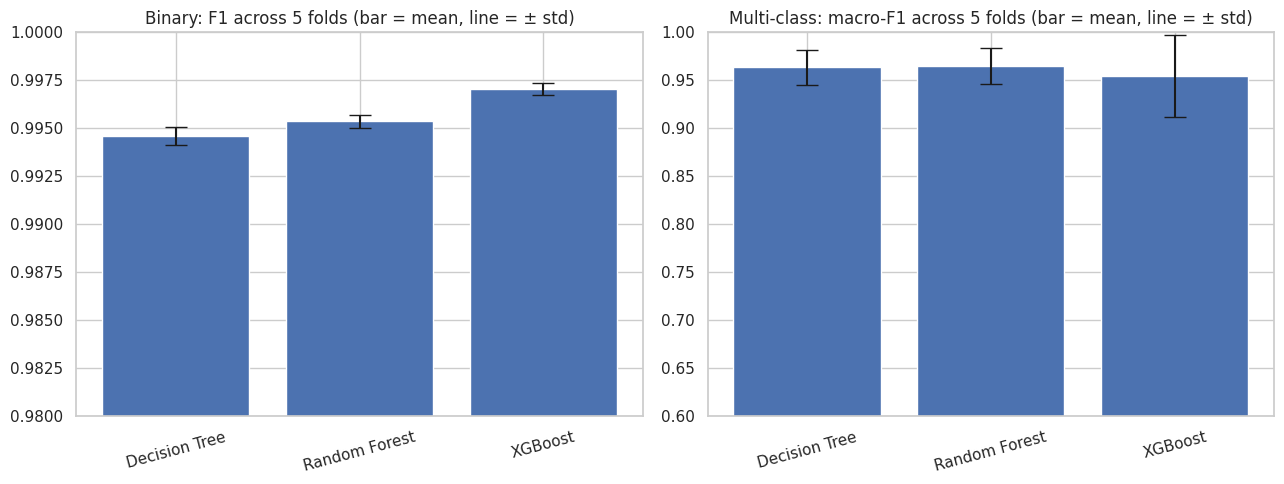

In [9]:
fold_df = pd.read_csv(FOLD_CSV)

def pm(s, nd=4):
    return f"{s.mean():.{nd}f} ± {s.std():.{nd}f}"

bin_rows, mc_rows = [], []
for (task, model), g in fold_df.groupby(["task", "model"]):
    if task == "binary":
        bin_rows.append({"model": model, "F1": pm(g["f1"]), "Precision": pm(g["precision"]),
                         "Recall": pm(g["recall"]), "PR-AUC": pm(g["pr_auc"]),
                         "sec per fold": round(g["train_seconds"].mean(), 1)})
    else:
        oof = np.load(METRIC_DIR / f"06a_oof_{model.replace(' ', '_')}_multiclass.npy")
        mc_rows.append({"model": model, "Macro-F1 (mean ± std)": pm(g["macro_f1"]),
                        "Weighted-F1": pm(g["weighted_f1"]),
                        "Pooled macro-F1 (every row judged once)": round(f1_score(y_multi, oof, average="macro"), 4),
                        "sec per fold": round(g["train_seconds"].mean(), 1)})

bin_summary, mc_summary = pd.DataFrame(bin_rows), pd.DataFrame(mc_rows)
print("BINARY (5-fold CV)\n", bin_summary.to_string(index=False))
print("\nMULTI-CLASS (5-fold CV)\n", mc_summary.to_string(index=False))
save_table(bin_summary, "06a_cv_summary_binary", index=False)
save_table(mc_summary, "06a_cv_summary_multiclass", index=False)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, task, col, lo, title in [(axes[0], "binary", "f1", 0.98, "Binary: F1 across 5 folds"),
                                 (axes[1], "multiclass", "macro_f1", 0.6, "Multi-class: macro-F1 across 5 folds")]:
    agg = fold_df[fold_df["task"] == task].groupby("model")[col].agg(["mean", "std"])
    ax.bar(agg.index, agg["mean"], yerr=agg["std"], capsize=8, color="#4C72B0")
    ax.set_ylim(lo, 1.0)
    ax.set_title(title + " (bar = mean, line = ± std)")
    ax.tick_params(axis="x", rotation=15)
save_fig("06a_cv_mean_std")
plt.show()

[saved table] /content/drive/MyDrive/network-intrusion-ml/results/tables/06a_cv_per_class_detail.csv
[saved figure] /content/drive/MyDrive/network-intrusion-ml/results/figures/06a_cv_per_class_f1_heatmap.png


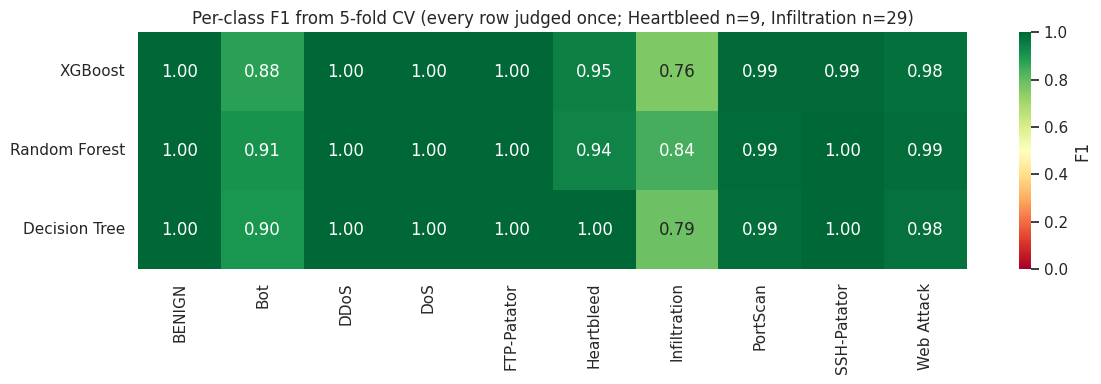

        model        class  precision  recall    f1  support
      XGBoost          Bot      0.868   0.883 0.875     1558
      XGBoost   Heartbleed      0.900   1.000 0.947        9
      XGBoost Infiltration      0.905   0.655 0.760       29
      XGBoost   Web Attack      0.985   0.980 0.982     1715
Random Forest          Bot      0.909   0.909 0.909     1558
Random Forest   Heartbleed      1.000   0.889 0.941        9
Random Forest Infiltration      1.000   0.724 0.840       29
Random Forest   Web Attack      0.995   0.977 0.986     1715
Decision Tree          Bot      0.896   0.901 0.899     1558
Decision Tree   Heartbleed      1.000   1.000 1.000        9
Decision Tree Infiltration      0.815   0.759 0.786       29
Decision Tree   Web Attack      0.980   0.978 0.979     1715


In [10]:
from sklearn.metrics import precision_recall_fscore_support

pc, detail = {}, []
for model in cv_models:
    oof = np.load(METRIC_DIR / f"06a_oof_{model.replace(' ', '_')}_multiclass.npy")
    p, r, f, s = precision_recall_fscore_support(
        y_multi, oof, labels=list(range(len(class_names))), zero_division=0)
    pc[model] = f
    for i, cn in enumerate(class_names):
        detail.append({"model": model, "class": cn, "precision": p[i], "recall": r[i],
                       "f1": f[i], "support": int(s[i])})

detail_df = pd.DataFrame(detail)
save_table(detail_df.round(4), "06a_cv_per_class_detail", index=False)

heat = pd.DataFrame(pc, index=class_names).T
plt.figure(figsize=(12, 4))
sns.heatmap(heat, annot=True, fmt=".2f", cmap="RdYlGn", vmin=0, vmax=1, cbar_kws={"label": "F1"})
plt.title("Per-class F1 from 5-fold CV (every row judged once; Heartbleed n=9, Infiltration n=29)")
plt.ylabel("")
save_fig("06a_cv_per_class_f1_heatmap")
plt.show()

print(detail_df[detail_df["class"].isin(["Bot", "Web Attack", "Infiltration", "Heartbleed"])]
      .round(3).to_string(index=False))

In [11]:
from src.utils import FIG_DIR
for p in sorted(TABLE_DIR.glob("06a_*")) + sorted(METRIC_DIR.glob("06a_*")) + sorted(FIG_DIR.glob("06a_*")):
    print(p.name)

06a_cv_fold_metrics.csv
06a_cv_per_class_detail.csv
06a_cv_summary_binary.csv
06a_cv_summary_multiclass.csv
06a_oof_Decision_Tree_binary.npy
06a_oof_Decision_Tree_multiclass.npy
06a_oof_Random_Forest_binary.npy
06a_oof_Random_Forest_multiclass.npy
06a_oof_XGBoost_binary.npy
06a_oof_XGBoost_multiclass.npy
06a_cv_mean_std.png
06a_cv_per_class_f1_heatmap.png
